## 0. Persiapan Lingkungan dan Dataset

In [1]:
# ==== IDENTITAS (ubah sesuai data Anda) ====
NAMA  = "Khansa Nisrina"
NIM   = "2330511089"          # SEED = 4 digit terakhir NIM
KELAS = "TI-7B"

import os, sys
SEED = int(NIM[-4:])
DI_COLAB = "google.colab" in sys.modules
ROOT = f"/content/simuteh-{NIM}" if DI_COLAB else os.path.abspath(f"simuteh-{NIM}")
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
os.chdir(ROOT)
print("Folder kerja :", ROOT)
print("SEED         :", SEED)

Folder kerja : /content/simuteh-2330511089
SEED         : 1089


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/    citra berwarna hasil "pemotretan" (dengan gangguan cahaya dan derau)
  bersih/   citra yang sama tanpa gangguan (acuan mutu)
  mask_daun/    mask area daun (255 = daun)
  mask_bercak/  mask area bercak penyakit (255 = bercak)
  label.csv     nama_file, kelas, kondisi_cahaya, persen_bercak
"""
import os
import csv
import cv2
import numpy as np

SEED = 1089          # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])               # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]               # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)    # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun                                # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)   # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)                   # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])      # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Writing src/buat_dataset_sintetis.py


In [5]:
# Pasang SEED sesuai NIM, bangkitkan dataset, lalu pindah ke folder notebook/
import re, subprocess
kode = open("src/buat_dataset_sintetis.py").read()
kode = re.sub(r"^SEED = \d+", f"SEED = {SEED}", kode, count=1, flags=re.M)
open("src/buat_dataset_sintetis.py", "w").write(kode)
keluaran = subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"],
                          capture_output=True, text=True)
print(keluaran.stdout, keluaran.stderr)

# requirements.txt untuk reprodusibilitas
import cv2, numpy, pandas, matplotlib, skimage, PIL
with open("requirements.txt", "w") as f:
    for nm, m in [("opencv-python", cv2), ("numpy", numpy), ("pandas", pandas),
                  ("matplotlib", matplotlib), ("scikit-image", skimage), ("pillow", PIL)]:
        f.write(f"{nm}=={m.__version__}\n")
print(open("requirements.txt").read())

os.chdir(os.path.join(ROOT, "notebook"))   # semua jalur selanjutnya diawali ../

Selesai: 60 citra tersimpan di data/sintetis
 
opencv-python==5.0.0
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-image==0.25.2
pillow==11.3.0



In [6]:
# Pustaka dan fungsi bantu yang dipakai di seluruh notebook
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90

def muat(nama, folder="citra"):
    """Mengembalikan (citra BGR, mask daun, mask bercak) untuk satu nama berkas."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| (satuan intensitas)."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.describe().round(2))

kondisi_cahaya  bayangan  gelap  kontras_rendah  normal  terang
kelas                                                          
berat                  4      4               4       4       4
ringan                 4      4               4       4       4
sehat                  4      4               4       4       4
        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  4.67  1.27  2.69  3.52  4.90  5.71  6.82
ringan   20.0  0.43  0.21  0.10  0.30  0.44  0.62  0.78
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


In [35]:
%%writefile ../src/utils_tepi.py
"""utils_tepi.py: fungsi bantu evaluasi deteksi tepi dan morfologi SIMUTEH."""

import cv2
import numpy as np


def tepi_acuan(mask):
    """Tepi acuan selebar 1 piksel dari sebuah mask biner."""
    m = (mask > 0).astype(np.uint8)
    return (
        ((m - cv2.erode(m, np.ones((3, 3), np.uint8))) > 0)
        .astype(np.uint8) * 255
    )


def skor_tepi(prediksi, acuan, toleransi=2):
    """Menghitung presisi, recall, dan F1 tepi dengan toleransi jarak."""
    p = prediksi > 0
    a = acuan > 0

    if p.sum() == 0 or a.sum() == 0:
        return 0.0, 0.0, 0.0

    jarak_ke_a = cv2.distanceTransform(
        (~a).astype(np.uint8), cv2.DIST_L2, 3
    )
    jarak_ke_p = cv2.distanceTransform(
        (~p).astype(np.uint8), cv2.DIST_L2, 3
    )

    presisi = float((jarak_ke_a[p] <= toleransi).mean())
    recall = float((jarak_ke_p[a] <= toleransi).mean())

    f1 = (
        0.0 if presisi + recall == 0
        else 2 * presisi * recall / (presisi + recall)
    )

    return round(presisi, 3), round(recall, 3), round(f1, 3)


def iou(a, b):
    """Intersection over Union dua mask biner."""
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()

    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)


def mask_daun_awal(img_bgr):
    """Mask daun sementara menggunakan ambang Otsu pada kanal saturasi."""
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]

    _, m = cv2.threshold(
        s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    return m


def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    """
    Citra biner bercak sementara.

    Piksel daun yang lebih terang dari median + k x MAD akan ditandai.
    """
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0

    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))

    return (((c > med + k * mad) & m) * 255).astype(np.uint8)

Writing ../src/utils_tepi.py


,citra,IoU daun awal,komponen bercak awal,komponen acuan,IoU bercak awal
0,teh_041.png,0.994,211,10,0.707
1,teh_021.png,0.996,191,3,0.187
2,teh_011.png,0.998,124,0,-


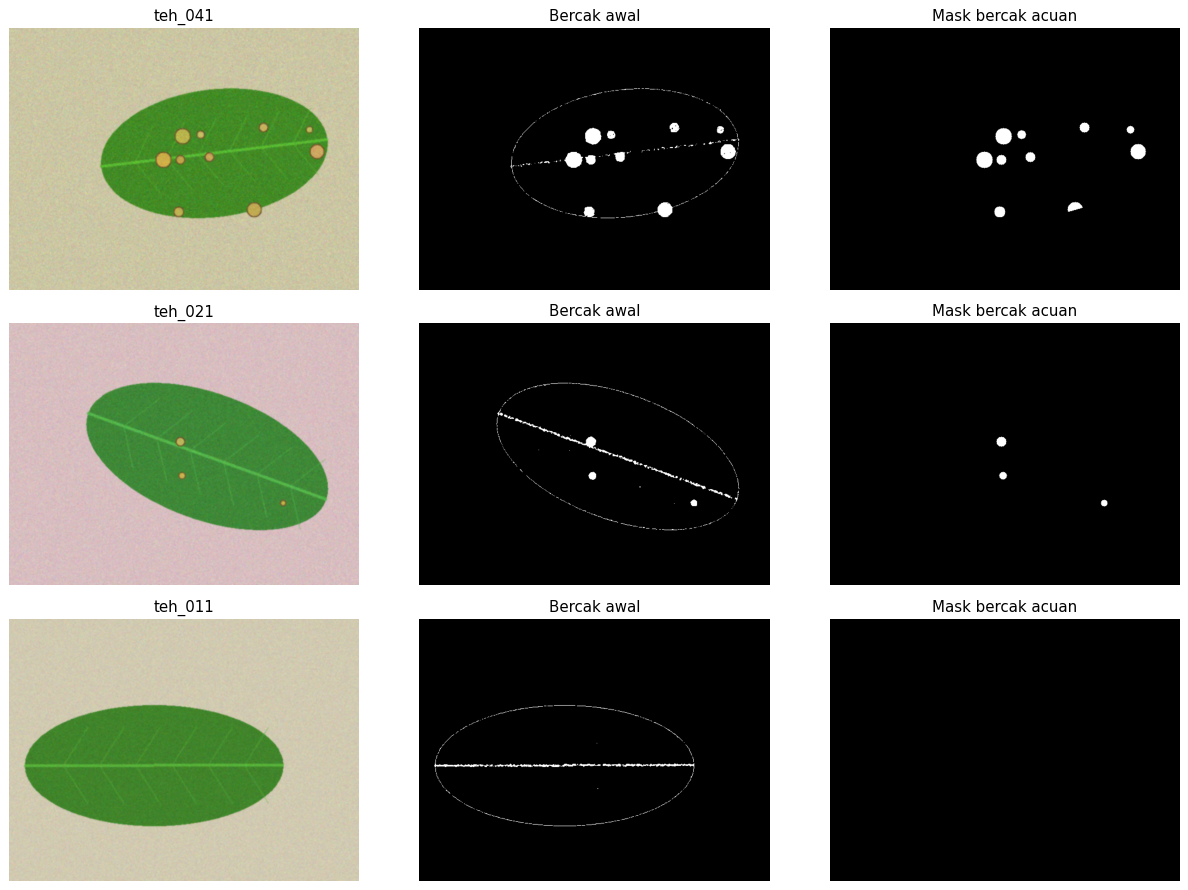

In [47]:
def jumlah_komponen(m, konek=8):
    return (
        cv2.connectedComponents(
            (m > 0).astype(np.uint8),
            connectivity=konek
        )[0] - 1
    )


p6_baris_awal = []
p6_panel_awal = []
p6_judul_awal = []

for p6_nama in [
    "teh_041.png",
    "teh_021.png",
    "teh_011.png"
]:

    p6_img_i, p6_md_i, p6_mb_i = muat(p6_nama)

    p6_pra_i = pp.praproses(
        p6_img_i,
        PARAM_P5
    )

    p6_m_daun = mask_daun_awal(p6_pra_i)

    p6_biner_awal = bercak_awal(
        p6_pra_i,
        p6_m_daun,
        kanal=2,
        k=4.0
    )

    p6_baris_awal.append([
        p6_nama,
        round(iou(p6_m_daun, p6_md_i), 3),
        jumlah_komponen(p6_biner_awal),
        jumlah_komponen(p6_mb_i),
        round(iou(p6_biner_awal, p6_mb_i), 3)
        if p6_mb_i.any() else "-"
    ])

    p6_panel_awal += [
        p6_pra_i,
        p6_biner_awal,
        p6_mb_i
    ]

    p6_judul_awal += [
        p6_nama[:7],
        "Bercak awal",
        "Mask bercak acuan"
    ]


p6_tabel_awal = pd.DataFrame(
    p6_baris_awal,
    columns=[
        "citra",
        "IoU daun awal",
        "komponen bercak awal",
        "komponen acuan",
        "IoU bercak awal"
    ]
)

display(p6_tabel_awal)

tampil(
    p6_panel_awal,
    p6_judul_awal,
    baris=3,
    ukuran=(14, 10)
)

plt.savefig(
    "../hasil/p6_mask_awal.png",
    bbox_inches="tight"
)
plt.show()

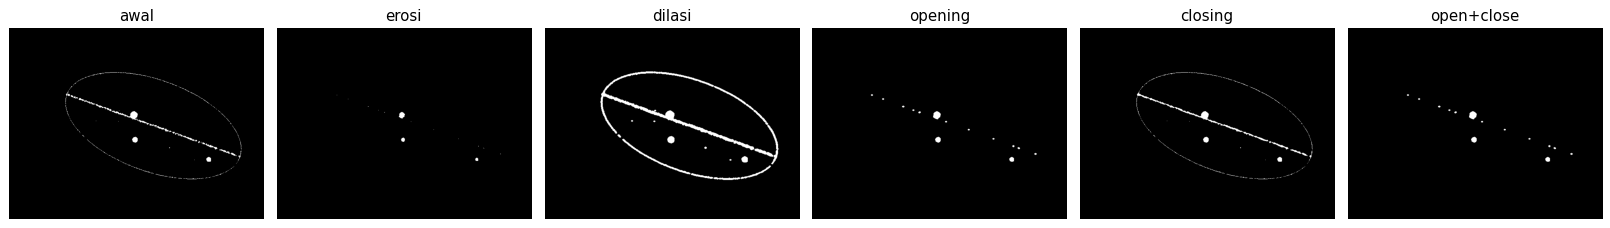

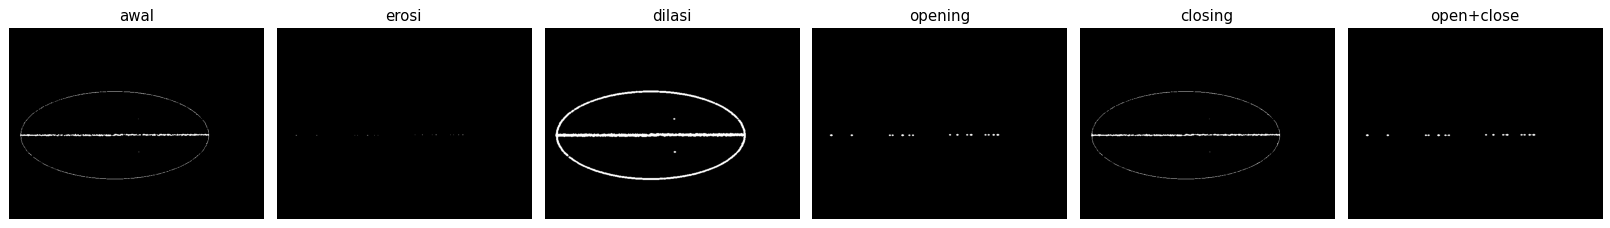

,citra,operasi,komponen,piksel,IoU
0,teh_021.png,awal,191,2729,0.187
1,teh_021.png,erosi,14,317,0.564
2,teh_021.png,dilasi,13,9471,0.054
3,teh_021.png,opening,14,771,0.649
4,teh_021.png,closing,155,2983,0.171
5,teh_021.png,open+close,14,771,0.649
6,teh_011.png,awal,124,2424,-
7,teh_011.png,erosi,15,26,-
8,teh_011.png,dilasi,3,8872,-
9,teh_011.png,opening,15,310,-


In [48]:
def p6_SE(k, bentuk=cv2.MORPH_ELLIPSE):
    return cv2.getStructuringElement(
        bentuk,
        (k, k)
    )


def p6_operasi(b, se):

    return {
        "awal": b,

        "erosi": cv2.erode(b, se),

        "dilasi": cv2.dilate(b, se),

        "opening": cv2.morphologyEx(
            b,
            cv2.MORPH_OPEN,
            se
        ),

        "closing": cv2.morphologyEx(
            b,
            cv2.MORPH_CLOSE,
            se
        ),

        "open+close": cv2.morphologyEx(
            cv2.morphologyEx(
                b,
                cv2.MORPH_OPEN,
                se
            ),
            cv2.MORPH_CLOSE,
            se
        )
    }


p6_baris_operasi = []

for p6_nama in [
    "teh_021.png",
    "teh_011.png"
]:

    p6_img_i, p6_md_i, p6_mb_i = muat(p6_nama)

    p6_pra_i = pp.praproses(
        p6_img_i,
        PARAM_P5
    )

    p6_m_daun = mask_daun_awal(p6_pra_i)

    p6_biner_awal = bercak_awal(
        p6_pra_i,
        p6_m_daun
    )

    p6_hasil_operasi = p6_operasi(
        p6_biner_awal,
        p6_SE(5)
    )

    for p6_nama_operasi, p6_mask in p6_hasil_operasi.items():

        p6_baris_operasi.append([
            p6_nama,
            p6_nama_operasi,
            jumlah_komponen(p6_mask),
            int((p6_mask > 0).sum()),
            round(iou(p6_mask, p6_mb_i), 3)
            if p6_mb_i.any() else "-"
        ])

    tampil(
        list(p6_hasil_operasi.values()),
        list(p6_hasil_operasi.keys()),
        ukuran=(18, 3)
    )

    plt.show()


p6_tabel_operasi = pd.DataFrame(
    p6_baris_operasi,
    columns=[
        "citra",
        "operasi",
        "komponen",
        "piksel",
        "IoU"
    ]
)

display(p6_tabel_operasi)

p6_tabel_operasi.to_csv(
    "../hasil/p6_tabel_operasi.csv",
    index=False
)

In [49]:
p6_bentuk_se = {
    "persegi": cv2.MORPH_RECT,
    "elips": cv2.MORPH_ELLIPSE,
    "silang": cv2.MORPH_CROSS
}

p6_baris_eksperimen = []

for _, d in label.iterrows():

    p6_img_i, p6_md_i, p6_mb_i = muat(d.nama_file)

    p6_pra_i = pp.praproses(
        p6_img_i,
        PARAM_P5
    )

    p6_m_daun = mask_daun_awal(p6_pra_i)

    p6_n_acuan = jumlah_komponen(p6_mb_i)

    for p6_k in [3, 4, 6]:

        p6_b0 = bercak_awal(
            p6_pra_i,
            p6_m_daun,
            k=p6_k
        )

        for p6_nama_bentuk, p6_kode_bentuk in p6_bentuk_se.items():

            for p6_ukuran in [3, 5, 7]:

                p6_se = p6_SE(
                    p6_ukuran,
                    p6_kode_bentuk
                )

                # Opening dilanjutkan closing
                p6_mask = cv2.morphologyEx(
                    cv2.morphologyEx(
                        p6_b0,
                        cv2.MORPH_OPEN,
                        p6_se
                    ),
                    cv2.MORPH_CLOSE,
                    p6_se
                )

                p6_baris_eksperimen.append([
                    d.kelas,
                    p6_k,
                    p6_nama_bentuk,
                    p6_ukuran,
                    abs(
                        jumlah_komponen(p6_mask) -
                        p6_n_acuan
                    ),
                    iou(p6_mask, p6_mb_i)
                    if p6_mb_i.any() else np.nan
                ])


p6_eksperimen_se = pd.DataFrame(
    p6_baris_eksperimen,
    columns=[
        "kelas",
        "k",
        "bentuk",
        "ukuran",
        "galat_jumlah",
        "IoU"
    ]
)

print("Ringkasan eksperimen structuring element:")

display(
    p6_eksperimen_se.pivot_table(
        index=["k", "bentuk", "ukuran"],
        columns="kelas",
        values=["galat_jumlah", "IoU"]
    ).round(2)
)

p6_eksperimen_se.to_csv(
    "../hasil/p6_eksperimen_se.csv",
    index=False
)

Ringkasan eksperimen structuring element:


IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.73   0.38        26.25  15.75  25.15
          5       0.78   0.55         2.30   4.45   4.15
          7       0.83   0.70         0.40   0.30   1.55
  persegi 3       0.75   0.43         7.95   8.60   7.50
          5       0.80   0.67         1.70   1.60   3.25
          7       0.80   0.63         0.60   0.20   0.00
  silang  3       0.73   0.38        26.25  15.75  25.15
          5       0.78   0.52         4.30   7.00   7.85
          7       0.83   0.67         1.10   0.90   2.85
4 elips   3       0.76   0.53        21.00  11.85  27.55
          5       0.80   0.71         2.60   1.10   3.05
          7       0.81   0.71         0.15   0.10   0.05
  persegi 3       0.78   0.59         5.05   6.60   9.45
          5       0.81   0.71         0.50   0.10   1.10
          7       0.78   0.62         0.50   0.20   0.00
  silang  3       0.76   0.53        21.00  11.85  27.55
          5       0.80   0.69         5.10   2.40   5.80
          7       0.82   0.67         0.25   0.20   0.35
6 elips   3       0.76   0.68        18.85   1.70  21.20
          5       0.75   0.67         0.15   0.15   0.00
          7       0.72   0.61         0.40   0.20   0.00
  persegi 3       0.76   0.69         2.90   0.30   4.80
          5       0.73   0.63         0.25   0.15   0.00
          7       0.68   0.55         1.05   0.30   0.00
  silang  3       0.76   0.68        18.85   1.70  21.20
          5       0.76   0.67         0.20   0.15   0.25
          7       0.73   0.59         0.40   0.25   0.00

In [50]:
p6_baris_gradien = []

for _, d in label.iterrows():

    p6_img_i, p6_md_i, p6_mb_i = muat(d.nama_file)

    p6_pra_i = pp.praproses(
        p6_img_i,
        PARAM_P5
    )

    p6_m_daun = mask_daun_awal(p6_pra_i)

    # Gradien morfologi (dilasi - erosi)
    p6_grad = cv2.morphologyEx(
        p6_m_daun,
        cv2.MORPH_GRADIENT,
        p6_SE(3)
    )

    # Canny pada citra Gray
    p6_canny = tepi_canny(
        cv2.cvtColor(
            p6_pra_i,
            cv2.COLOR_BGR2GRAY
        )
    )

    p6_ad = tepi_acuan(p6_md_i)

    p6_baris_gradien.append([
        d.kondisi_cahaya,
        skor_tepi(p6_grad, p6_ad)[2],
        skor_tepi(p6_canny, p6_ad)[2]
    ])


p6_tabel_gradien = pd.DataFrame(
    p6_baris_gradien,
    columns=[
        "kondisi",
        "F1 gradien morfologi",
        "F1 Canny"
    ]
)

display(
    p6_tabel_gradien
    .groupby("kondisi")
    .mean()
    .round(3)
)

p6_tabel_gradien.to_csv(
    "../hasil/p6_gradien_morfologi.csv",
    index=False
)

,F1 gradien morfologi,F1 Canny
kondisi,,
bayangan,0.958,0.872
gelap,0.970,0.898
kontras_rendah,0.341,0.000
normal,0.990,0.929
terang,0.985,0.933


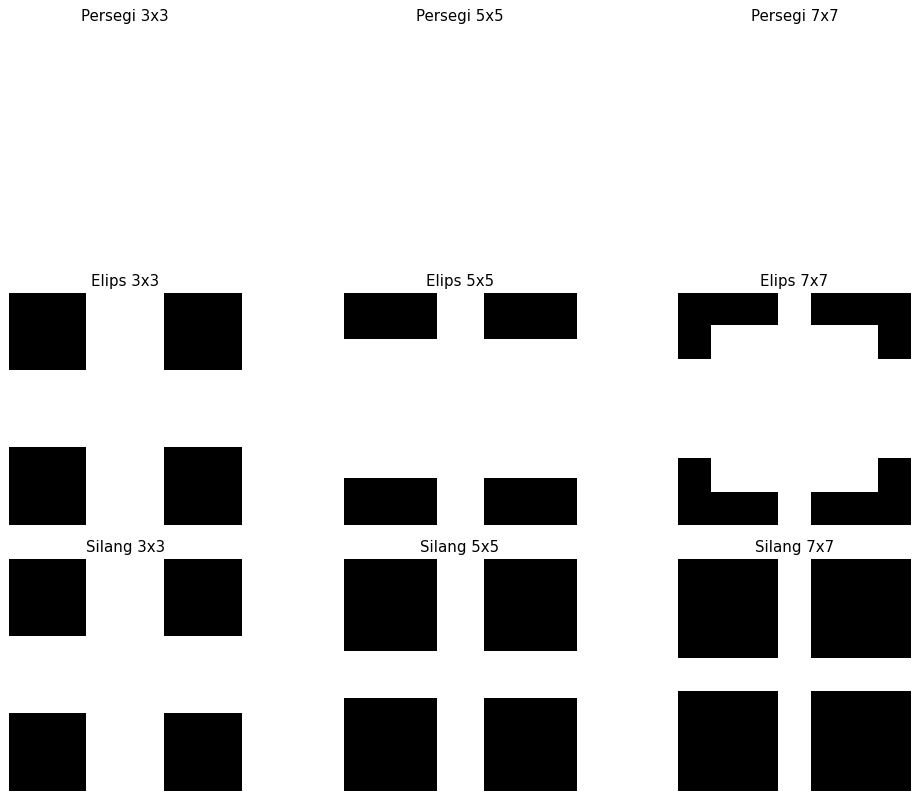

In [51]:
p6_nama_bentuk = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

p6_panel_se = []
p6_judul_se = []

for p6_nama, p6_bentuk in p6_nama_bentuk.items():

    for p6_ukuran in [3, 5, 7]:

        p6_kernel = cv2.getStructuringElement(
            p6_bentuk,
            (p6_ukuran, p6_ukuran)
        )

        p6_panel_se.append(
            p6_kernel * 255
        )

        p6_judul_se.append(
            f"{p6_nama} {p6_ukuran}x{p6_ukuran}"
        )


tampil(
    p6_panel_se,
    p6_judul_se,
    baris=3,
    ukuran=(12, 9)
)

plt.savefig(
    "../hasil/p6_panel_structuring_element.png",
    bbox_inches="tight"
)
plt.show()

In [52]:
MM_PER_PX = 0.4375


def ukur_komponen(m, konek=8):

    n, lbl, st, cen = cv2.connectedComponentsWithStats(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )

    baris_komponen = []

    for i in range(1, n):

        kontur, _ = cv2.findContours(
            (lbl == i).astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_NONE
        )

        if len(kontur) == 0:
            continue

        # Luas komponen
        A = int(st[i, cv2.CC_STAT_AREA])

        # Keliling
        keliling = cv2.arcLength(
            kontur[0],
            True
        )

        # Kebulatan
        kebulatan = (
            0.0 if keliling == 0
            else 4 * np.pi * A / keliling ** 2
        )

        # Rasio aspek
        w, h = cv2.minAreaRect(kontur[0])[1]

        rasio = (
            max(w, h) /
            max(min(w, h), 1)
        )

        baris_komponen.append([
            i,
            A,
            round(A * MM_PER_PX ** 2, 2),
            round(keliling, 1),
            round(kebulatan, 2),
            round(rasio, 2),
            int(cen[i][0]),
            int(cen[i][1])
        ])

    kolom = [
        "label",
        "luas_px",
        "luas_mm2",
        "keliling_px",
        "kebulatan",
        "rasio_aspek",
        "cx",
        "cy"
    ]

    return pd.DataFrame(
        baris_komponen,
        columns=kolom
    ), lbl

Konektivitas 4: 10 komponen
Konektivitas 8: 10 komponen
Tabel ukuran setiap bercak:


,label,luas_px,luas_mm2,keliling_px,kebulatan,rasio_aspek,cx,cy
0,1,221,42.30,57.2,0.85,1.00,465,182
1,2,122,23.35,41.0,0.91,1.22,549,187
2,3,702,134.37,97.8,0.92,1.07,316,198
3,4,169,32.35,48.4,0.91,1.05,349,196
4,5,600,114.84,89.6,0.94,1.04,563,226
5,6,700,133.98,99.3,0.89,1.05,281,241
6,7,259,49.57,58.4,0.95,1.06,366,236
7,8,244,46.70,57.2,0.94,1.06,312,241
8,9,575,110.06,87.0,0.95,1.00,447,333
9,10,286,54.74,62.6,0.92,1.00,309,336


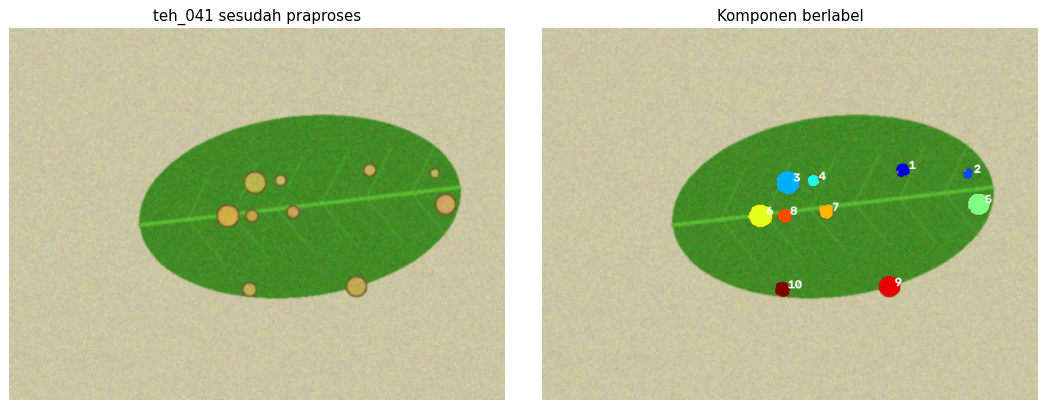

In [53]:
p6_img_041, p6_md_041, p6_mb_041 = muat(
    "teh_041.png"
)

p6_pra_041 = pp.praproses(
    p6_img_041,
    PARAM_P5
)

p6_m_daun_041 = mask_daun_awal(
    p6_pra_041
)

p6_bersih_041 = cv2.morphologyEx(
    cv2.morphologyEx(
        bercak_awal(
            p6_pra_041,
            p6_m_daun_041
        ),
        cv2.MORPH_OPEN,
        p6_SE(5)
    ),
    cv2.MORPH_CLOSE,
    p6_SE(5)
)


# Membandingkan konektivitas 4 dan 8
for p6_konek in [4, 8]:

    print(
        f"Konektivitas {p6_konek}: "
        f"{jumlah_komponen(p6_bersih_041, p6_konek)} komponen"
    )


# Mengukur setiap bercak dengan konektivitas 8
p6_tabel_komponen, p6_label_komponen = ukur_komponen(
    p6_bersih_041
)

print("Tabel ukuran setiap bercak:")
display(p6_tabel_komponen)


# Membuat citra dengan komponen berlabel
p6_maks_label = max(
    int(p6_label_komponen.max()),
    1
)

p6_warna = cv2.applyColorMap(
    (
        p6_label_komponen.astype(np.float32) *
        (255.0 / p6_maks_label)
    ).astype(np.uint8),
    cv2.COLORMAP_JET
)

p6_warna[p6_label_komponen == 0] = (
    p6_pra_041[p6_label_komponen == 0]
)


for _, p6_r in p6_tabel_komponen.iterrows():

    cv2.putText(
        p6_warna,
        str(int(p6_r.label)),
        (int(p6_r.cx) + 8, int(p6_r.cy)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 255),
        2
    )


tampil(
    [p6_pra_041, p6_warna],
    [
        "teh_041 sesudah praproses",
        "Komponen berlabel"
    ],
    ukuran=(12, 4.5)
)

plt.savefig(
    "../hasil/p6_komponen_berlabel.png",
    bbox_inches="tight"
)
plt.show()

p6_tabel_komponen.to_csv(
    "../hasil/p6_ukuran_bercak_teh041.csv",
    index=False
)

In [54]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):

    tabel_k, lbl = ukur_komponen(m)

    lolos = tabel_k[
        (tabel_k.luas_px >= luas_min) &
        (tabel_k.kebulatan >= bulat_min) &
        (tabel_k.rasio_aspek <= rasio_maks)
    ]

    return (
        (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8),
        lolos
    )


p6_aturan = {
    "tanpa saring": (0, 0, 99),
    "luas >= 20": (20, 0, 99),
    "luas + kebulatan": (20, 0.5, 99),
    "luas + kebulatan + rasio": (20, 0.5, 1.8)
}


p6_baris_saring = []

for _, d in label.iterrows():

    p6_img_i, p6_md_i, p6_mb_i = muat(d.nama_file)

    p6_pra_i = pp.praproses(
        p6_img_i,
        PARAM_P5
    )

    p6_m_daun = mask_daun_awal(p6_pra_i)

    p6_bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(
                p6_pra_i,
                p6_m_daun
            ),
            cv2.MORPH_OPEN,
            p6_SE(5)
        ),
        cv2.MORPH_CLOSE,
        p6_SE(5)
    )

    for p6_nama_aturan, (p6_a, p6_b, p6_r) in p6_aturan.items():

        p6_f, p6_lolos = saring(
            p6_bersih,
            p6_a,
            p6_b,
            p6_r
        )

        p6_baris_saring.append([
            d.kelas,
            p6_nama_aturan,
            jumlah_komponen(p6_f),
            jumlah_komponen(p6_mb_i)
        ])


p6_uji_saring = pd.DataFrame(
    p6_baris_saring,
    columns=[
        "kelas",
        "aturan",
        "jumlah",
        "acuan"
    ]
)

p6_uji_saring["galat"] = (
    p6_uji_saring["jumlah"] -
    p6_uji_saring["acuan"]
).abs()


print("Galat jumlah komponen berdasarkan aturan:")
display(
    p6_uji_saring.pivot_table(
        index="aturan",
        columns="kelas",
        values="galat"
    ).round(2)
)


print("Daun sehat yang masih memiliki bercak palsu:")

display(
    p6_uji_saring[
        p6_uji_saring.kelas == "sehat"
    ]
    .assign(
        palsu=lambda t: t.jumlah > 0
    )
    .groupby("aturan")["palsu"]
    .sum()
)


p6_uji_saring.to_csv(
    "../hasil/p6_uji_penyaringan.csv",
    index=False
)

Galat jumlah komponen berdasarkan aturan:


kelas,berat,ringan,sehat
aturan,,,
luas + kebulatan,1.40,0.45,1.25
luas + kebulatan + rasio,0.75,0.40,0.55
luas >= 20,1.90,0.45,2.25
tanpa saring,2.60,1.10,3.05


Daun sehat yang masih memiliki bercak palsu:


,palsu
aturan,
luas + kebulatan,8
luas + kebulatan + rasio,6
luas >= 20,8
tanpa saring,9


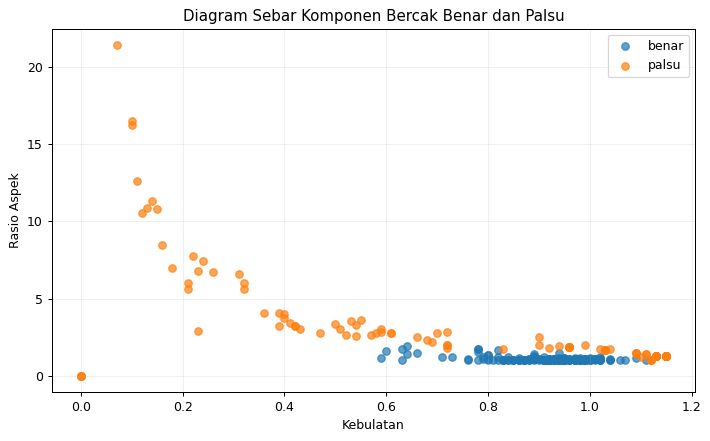

,nama,kelas,label,luas_px,kebulatan,rasio_aspek,proporsi_acuan,status
0,teh_003.png,sehat,1,43.0,0.42,3.24,0.0,palsu
1,teh_003.png,sehat,2,17.0,1.15,1.25,0.0,palsu
2,teh_003.png,sehat,3,22.0,1.13,1.25,0.0,palsu
3,teh_005.png,sehat,1,17.0,1.15,1.25,0.0,palsu
4,teh_006.png,sehat,1,26.0,1.12,1.00,0.0,palsu
5,teh_010.png,sehat,1,26.0,0.96,1.87,0.0,palsu
6,teh_010.png,sehat,2,34.0,1.02,1.70,0.0,palsu
7,teh_010.png,sehat,3,17.0,1.15,1.25,0.0,palsu
8,teh_011.png,sehat,1,27.0,1.09,1.50,0.0,palsu
9,teh_011.png,sehat,2,22.0,1.13,1.25,0.0,palsu


In [55]:
p6_baris_sebar = []

for _, d in label.iterrows():

    p6_img_i, p6_md_i, p6_mb_i = muat(d.nama_file)

    p6_pra_i = pp.praproses(
        p6_img_i,
        PARAM_P5
    )

    p6_m_daun = mask_daun_awal(p6_pra_i)

    p6_biner = bercak_awal(
        p6_pra_i,
        p6_m_daun
    )

    p6_bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            p6_biner,
            cv2.MORPH_OPEN,
            p6_SE(5)
        ),
        cv2.MORPH_CLOSE,
        p6_SE(5)
    )

    p6_tabel_k, p6_lbl = ukur_komponen(
        p6_bersih
    )

    for _, p6_r in p6_tabel_k.iterrows():

        p6_id = int(p6_r["label"])
        p6_mask_komponen = p6_lbl == p6_id

        p6_luas_komponen = int(
            p6_mask_komponen.sum()
        )

        p6_tumpang_tindih = int(
            (
                p6_mask_komponen &
                (p6_mb_i > 0)
            ).sum()
        )

        p6_proporsi = (
            p6_tumpang_tindih /
            max(p6_luas_komponen, 1)
        )

        p6_status = (
            "benar"
            if p6_proporsi > 0.5
            else "palsu"
        )

        p6_baris_sebar.append([
            d.nama_file,
            d.kelas,
            p6_id,
            p6_r["luas_px"],
            p6_r["kebulatan"],
            p6_r["rasio_aspek"],
            p6_proporsi,
            p6_status
        ])


p6_komponen_sebar = pd.DataFrame(
    p6_baris_sebar,
    columns=[
        "nama",
        "kelas",
        "label",
        "luas_px",
        "kebulatan",
        "rasio_aspek",
        "proporsi_acuan",
        "status"
    ]
)


# Diagram sebar kebulatan terhadap rasio aspek
plt.figure(figsize=(8, 5))

for p6_status in ["benar", "palsu"]:

    p6_data = p6_komponen_sebar[
        p6_komponen_sebar.status == p6_status
    ]

    plt.scatter(
        p6_data["kebulatan"],
        p6_data["rasio_aspek"],
        label=p6_status,
        alpha=0.7
    )


plt.xlabel("Kebulatan")
plt.ylabel("Rasio Aspek")
plt.title("Diagram Sebar Komponen Bercak Benar dan Palsu")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "../hasil/p6_sebar_komponen_benar_palsu.png",
    bbox_inches="tight"
)
plt.show()


display(p6_komponen_sebar.head(20))

p6_komponen_sebar.to_csv(
    "../hasil/p6_komponen_benar_palsu.csv",
    index=False
)

In [56]:
%%writefile ../src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""

import os
import json
import cv2
import numpy as np

from utils_tepi import mask_daun_awal, bercak_awal


PARAM_BERCAK = {
    "kanal": 2,
    "k": 4.0,
    "se_bentuk": "elips",
    "se_open": 5,
    "se_close": 5,
    "luas_min": 20,
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,
    "batas_berat": 2.0,
    "mm_per_px": 0.4375
}


_BENTUK = {
    "elips": cv2.MORPH_ELLIPSE,
    "persegi": cv2.MORPH_RECT,
    "silang": cv2.MORPH_CROSS
}


def _se(p, uk):
    """Membuat structuring element berdasarkan parameter."""
    return cv2.getStructuringElement(
        _BENTUK[p["se_bentuk"]],
        (uk, uk)
    )


def bersihkan(biner, p):
    """
    Membersihkan citra biner menggunakan opening dan closing.
    Opening membuang titik derau dan komponen tipis.
    Closing menutup celah pada komponen.
    """

    hasil = biner.copy()

    # TODO 1: Opening
    if p["se_open"] > 0:

        se_open = _se(
            p,
            p["se_open"]
        )

        hasil = cv2.morphologyEx(
            hasil,
            cv2.MORPH_OPEN,
            se_open
        )

    # TODO 2: Closing
    if p["se_close"] > 0:

        se_close = _se(
            p,
            p["se_close"]
        )

        hasil = cv2.morphologyEx(
            hasil,
            cv2.MORPH_CLOSE,
            se_close
        )

    return hasil


def ukur_dan_saring(biner, p):
    """
    Melabeli komponen terhubung, mengukur bentuknya,
    lalu menyaring komponen berdasarkan parameter.
    """

    # TODO 3: Label komponen terhubung
    n, lbl, st, cen = cv2.connectedComponentsWithStats(
        (biner > 0).astype(np.uint8),
        connectivity=8
    )

    keluar = np.zeros_like(biner)
    daftar = []

    # Mengabaikan label 0 karena merupakan latar belakang
    for i in range(1, n):

        mask_komponen = (
            (lbl == i).astype(np.uint8)
        )

        kontur, _ = cv2.findContours(
            mask_komponen,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_NONE
        )

        if len(kontur) == 0:
            continue

        # TODO 4: Menghitung ukuran dan bentuk komponen

        luas = int(
            st[i, cv2.CC_STAT_AREA]
        )

        keliling = cv2.arcLength(
            kontur[0],
            True
        )

        kebulatan = (
            0.0
            if keliling == 0
            else 4 * np.pi * luas / keliling ** 2
        )

        w, h = cv2.minAreaRect(
            kontur[0]
        )[1]

        rasio = (
            max(w, h) /
            max(min(w, h), 1)
        )

        # TODO 5: Penyaringan komponen
        if (
            luas >= p["luas_min"]
            and kebulatan >= p["bulat_min"]
            and rasio <= p["rasio_maks"]
        ):

            keluar[lbl == i] = 255

            # Menyimpan informasi komponen yang lolos
            daftar.append({

                "label": int(i),

                "luas_px": luas,

                "luas_mm2": round(
                    luas * p["mm_per_px"] ** 2,
                    2
                ),

                "keliling_px": round(
                    float(keliling),
                    1
                ),

                "kebulatan": round(
                    float(kebulatan),
                    2
                ),

                "rasio_aspek": round(
                    float(rasio),
                    2
                ),

                "cx": int(cen[i][0]),

                "cy": int(cen[i][1])
            })

    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """
    Masukan:
        Citra BGR hasil praproses.

    Keluaran:
        Mask daun, mask bercak, jumlah bercak,
        persentase bercak, kelas mutu, dan ukuran bercak.
    """

    p = {
        **PARAM_BERCAK,
        **(p or {})
    }

    # Membuat mask daun
    m_daun = mask_daun_awal(
        img_praproses
    )

    # Membuat citra biner bercak awal
    biner = bercak_awal(
        img_praproses,
        m_daun,
        kanal=p["kanal"],
        k=p["k"]
    )

    # Membersihkan citra biner
    hasil_bersih = bersihkan(
        biner,
        p
    )

    # Mengukur dan menyaring setiap bercak
    m_bercak, daftar = ukur_dan_saring(
        hasil_bersih,
        p
    )

    # TODO 6: Menghitung persentase bercak
    luas_daun = int(
        (m_daun > 0).sum()
    )

    luas_bercak = int(
        (m_bercak > 0).sum()
    )

    persen = (
        0.0
        if luas_daun == 0
        else (luas_bercak / luas_daun) * 100
    )

    # TODO 7: Menentukan kelas mutu
    if persen >= p["batas_berat"]:

        kelas = "Bercak Berat"

    elif persen >= p["batas_ringan"]:

        kelas = "Bercak Ringan"

    else:

        kelas = "Sehat"

    return {
        "mask_daun": m_daun,
        "mask_bercak": m_bercak,
        "jumlah_bercak": len(daftar),
        "persen_bercak": round(float(persen), 3),
        "kelas": kelas,
        "bercak": daftar
    }


def simpan_param(p, path="../hasil/param_bercak.json"):

    os.makedirs(
        os.path.dirname(path) or ".",
        exist_ok=True
    )

    with open(path, "w") as f:

        json.dump(
            {
                **PARAM_BERCAK,
                **(p or {})
            },
            f,
            indent=2
        )

Writing ../src/bercak.py


Galat absolut rerata persen bercak: 0.284
Korelasi persen prediksi vs acuan: 0.97
Akurasi kelas: 0.917
Matriks kekeliruan:


Prediksi,Bercak Berat,Bercak Ringan,Sehat
Acuan,,,
Bercak Berat,19,1,0
Bercak Ringan,0,17,3
Sehat,0,1,19


Akurasi per kondisi cahaya:


,benar
kondisi,
bayangan,0.917
gelap,1.000
kontras_rendah,0.750
normal,0.917
terang,1.000


Jumlah daun sehat yang dinilai berbercak: 1
Jumlah daun berbercak yang dinilai sehat: 3
Kondisi cahaya dengan akurasi terendah: kontras_rendah


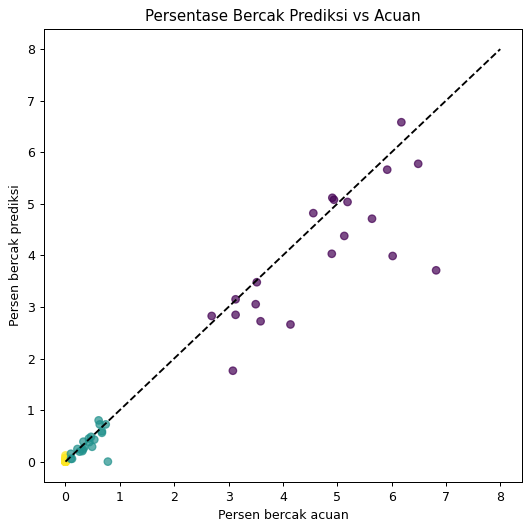

In [57]:
import importlib
import bercak

importlib.reload(bercak)

# Parameter hasil eksperimen.
# Kosong berarti menggunakan parameter bawaan dari bercak.py.
P6_PB = {}

# Menyimpan parameter final
bercak.simpan_param(P6_PB)


p6_baris_evaluasi = []

for _, d in label.iterrows():

    p6_img_i, p6_md_i, p6_mb_i = muat(
        d.nama_file
    )

    # Praproses dari modul P1-P4
    p6_pra_i = pp.praproses(
        p6_img_i,
        PARAM_P5
    )

    # Analisis bercak
    p6_hasil = bercak.analisis_daun(
        p6_pra_i,
        P6_PB
    )

    p6_baris_evaluasi.append([

        d.nama_file,

        d.kelas,

        d.kondisi_cahaya,

        d.persen_bercak,

        p6_hasil["persen_bercak"],

        jumlah_komponen(p6_mb_i),

        p6_hasil["jumlah_bercak"],

        p6_hasil["kelas"]
    ])


p6_ev_bercak = pd.DataFrame(
    p6_baris_evaluasi,
    columns=[
        "nama",
        "kelas",
        "kondisi",
        "persen_acuan",
        "persen_prediksi",
        "jumlah_acuan",
        "jumlah_prediksi",
        "kelas_prediksi"
    ]
)


# Mengubah nama kelas acuan agar sesuai dengan kelas prediksi
p6_ev_bercak["kelas_acuan"] = (
    p6_ev_bercak["kelas"].map({
        "sehat": "Sehat",
        "ringan": "Bercak Ringan",
        "berat": "Bercak Berat"
    })
)


# Menyimpan hasil evaluasi
p6_ev_bercak.to_csv(
    "../hasil/p6_evaluasi_bercak.csv",
    index=False
)


# 1. Galat absolut rerata persentase bercak
p6_galat_persen = (
    p6_ev_bercak["persen_prediksi"] -
    p6_ev_bercak["persen_acuan"]
).abs().mean()

print(
    "Galat absolut rerata persen bercak:",
    round(p6_galat_persen, 3)
)


# 2. Korelasi prediksi dan acuan
p6_korelasi = (
    p6_ev_bercak[
        ["persen_prediksi", "persen_acuan"]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Korelasi persen prediksi vs acuan:",
    round(p6_korelasi, 3)
)


# 3. Akurasi kelas
p6_akurasi = (
    p6_ev_bercak["kelas_prediksi"] ==
    p6_ev_bercak["kelas_acuan"]
).mean()

print(
    "Akurasi kelas:",
    round(p6_akurasi, 3)
)


# 4. Matriks kekeliruan
p6_matriks = pd.crosstab(
    p6_ev_bercak["kelas_acuan"],
    p6_ev_bercak["kelas_prediksi"],
    rownames=["Acuan"],
    colnames=["Prediksi"]
)

print("Matriks kekeliruan:")
display(p6_matriks)

p6_matriks.to_csv(
    "../hasil/p6_matriks_kekeliruan.csv"
)


# 5. Akurasi berdasarkan kondisi cahaya
p6_akurasi_kondisi = (
    p6_ev_bercak
    .assign(
        benar=lambda t:
        t.kelas_prediksi == t.kelas_acuan
    )
    .groupby("kondisi")["benar"]
    .mean()
)

print("Akurasi per kondisi cahaya:")
display(p6_akurasi_kondisi.round(3))


# 6. Jumlah daun sehat yang salah dinilai berbercak
p6_salah_sehat = (
    (
        p6_ev_bercak["kelas_acuan"] == "Sehat"
    ) &
    (
        p6_ev_bercak["kelas_prediksi"] != "Sehat"
    )
).sum()


# 7. Jumlah daun berbercak yang salah dinilai sehat
p6_salah_bercak = (
    (
        p6_ev_bercak["kelas_acuan"] != "Sehat"
    ) &
    (
        p6_ev_bercak["kelas_prediksi"] == "Sehat"
    )
).sum()


print(
    "Jumlah daun sehat yang dinilai berbercak:",
    p6_salah_sehat
)

print(
    "Jumlah daun berbercak yang dinilai sehat:",
    p6_salah_bercak
)


# Kondisi dengan akurasi terendah
print(
    "Kondisi cahaya dengan akurasi terendah:",
    p6_akurasi_kondisi.idxmin()
)


# Diagram sebar persen bercak prediksi vs acuan
plt.figure(figsize=(6, 6))

plt.scatter(
    p6_ev_bercak["persen_acuan"],
    p6_ev_bercak["persen_prediksi"],
    c=p6_ev_bercak["kelas"].astype("category").cat.codes,
    alpha=0.7
)

plt.plot(
    [0, 8],
    [0, 8],
    "k--"
)

plt.xlabel("Persen bercak acuan")
plt.ylabel("Persen bercak prediksi")
plt.title("Persentase Bercak Prediksi vs Acuan")

plt.tight_layout()

plt.savefig(
    "../hasil/p6_persen_prediksi_vs_acuan.png",
    bbox_inches="tight"
)

plt.show()

Jumlah citra yang salah diklasifikasikan: 5
Nama citra: teh_011.png
Kelas acuan: Sehat
Kelas prediksi: Bercak Ringan
Persen bercak acuan: 0.0
Persen bercak prediksi: 0.12


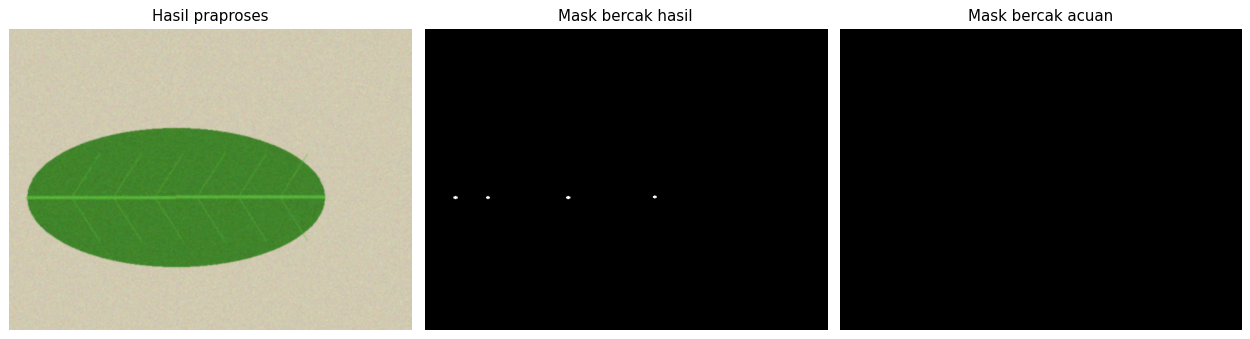

Nama citra: teh_025.png
Kelas acuan: Bercak Ringan
Kelas prediksi: Sehat
Persen bercak acuan: 0.12
Persen bercak prediksi: 0.055


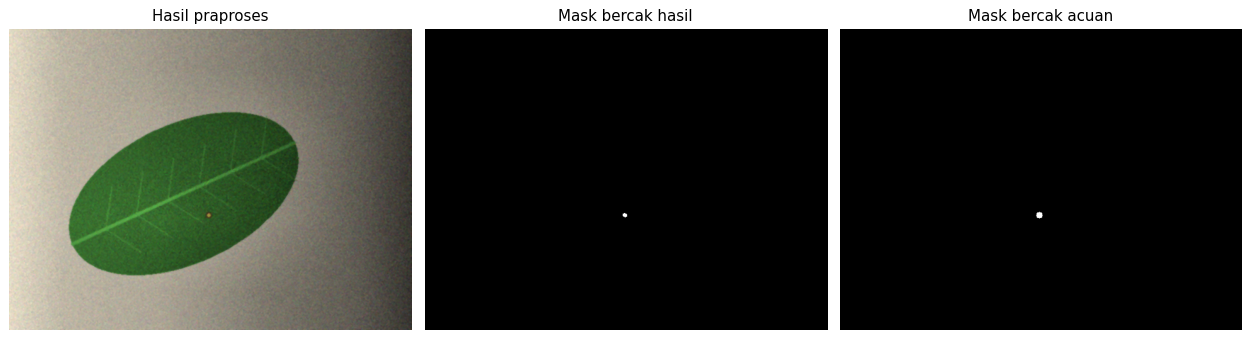

Nama citra: teh_029.png
Kelas acuan: Bercak Ringan
Kelas prediksi: Sehat
Persen bercak acuan: 0.1
Persen bercak prediksi: 0.054


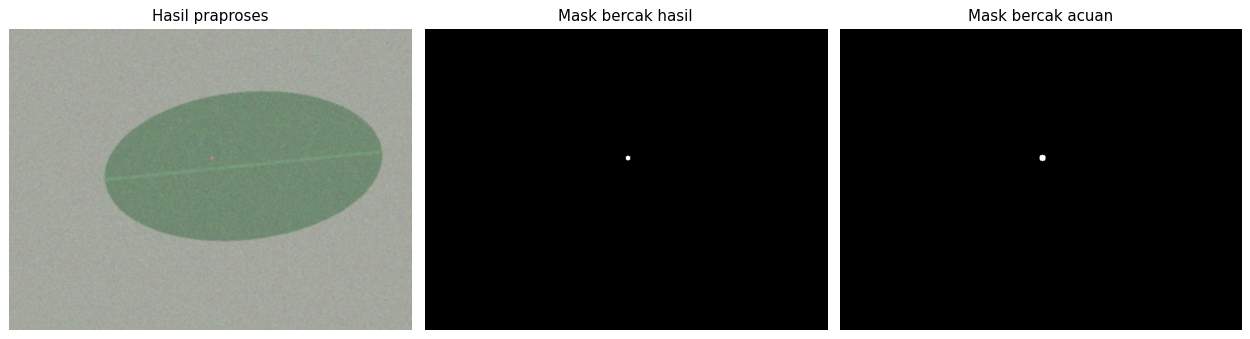

Nama citra: teh_034.png
Kelas acuan: Bercak Ringan
Kelas prediksi: Sehat
Persen bercak acuan: 0.78
Persen bercak prediksi: 0.0


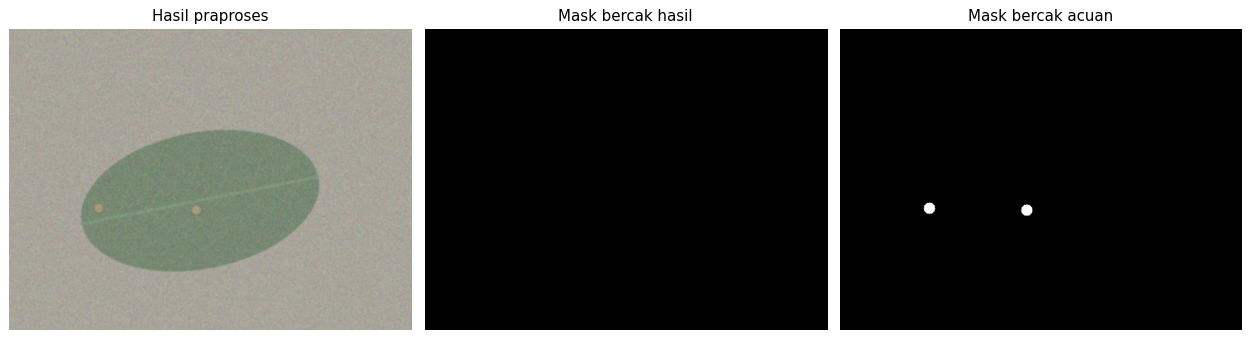

Nama citra: teh_044.png
Kelas acuan: Bercak Berat
Kelas prediksi: Bercak Ringan
Persen bercak acuan: 3.08
Persen bercak prediksi: 1.763


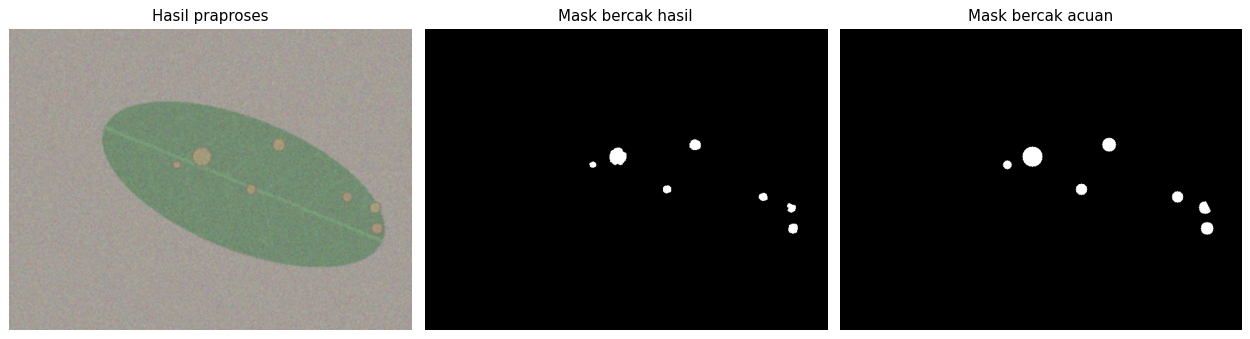

In [58]:
p6_citra_salah = p6_ev_bercak[
    p6_ev_bercak["kelas_prediksi"] !=
    p6_ev_bercak["kelas_acuan"]
]

print(
    "Jumlah citra yang salah diklasifikasikan:",
    len(p6_citra_salah)
)


for _, d in p6_citra_salah.iterrows():

    p6_img_i, p6_md_i, p6_mb_i = muat(
        d.nama
    )

    p6_pra_i = pp.praproses(
        p6_img_i,
        PARAM_P5
    )

    p6_hasil = bercak.analisis_daun(
        p6_pra_i,
        P6_PB
    )

    print("Nama citra:", d.nama)
    print("Kelas acuan:", d.kelas_acuan)
    print("Kelas prediksi:", d.kelas_prediksi)

    print(
        "Persen bercak acuan:",
        d.persen_acuan
    )

    print(
        "Persen bercak prediksi:",
        d.persen_prediksi
    )

    tampil(
        [
            p6_pra_i,
            p6_hasil["mask_bercak"],
            p6_mb_i
        ],
        [
            "Hasil praproses",
            "Mask bercak hasil",
            "Mask bercak acuan"
        ],
        ukuran=(14, 4)
    )

    plt.show()

In [59]:
p6_parameter_final = {
    **bercak.PARAM_BERCAK,
    **P6_PB
}

p6_justifikasi = pd.DataFrame([

    [
        "kanal dan k",
        f"{p6_parameter_final['kanal']} dan {p6_parameter_final['k']}",
        "",
        ""
    ],

    [
        "se_bentuk, se_open, se_close",
        f"{p6_parameter_final['se_bentuk']}, "
        f"{p6_parameter_final['se_open']}, "
        f"{p6_parameter_final['se_close']}",
        "",
        ""
    ],

    [
        "luas_min",
        p6_parameter_final["luas_min"],
        "",
        ""
    ],

    [
        "bulat_min dan rasio_maks",
        f"{p6_parameter_final['bulat_min']} dan "
        f"{p6_parameter_final['rasio_maks']}",
        "",
        ""
    ],

    [
        "batas_ringan dan batas_berat",
        f"{p6_parameter_final['batas_ringan']}% dan "
        f"{p6_parameter_final['batas_berat']}%",
        "",
        ""
    ]

], columns=[
    "Parameter",
    "Nilai final",
    "Alasan dan bukti",
    "Risiko bila salah atur"
])

display(p6_justifikasi)

p6_justifikasi.to_csv(
    "../hasil/p6_justifikasi_parameter.csv",
    index=False
)

,Parameter,Nilai final,Alasan dan bukti,Risiko bila salah atur
0,kanal dan k,2 dan 4.0,,
1,"se_bentuk, se_open, se_close","elips, 5, 5",,
2,luas_min,20,,
3,bulat_min dan rasio_maks,0.5 dan 1.8,,
4,batas_ringan dan batas_berat,0.1% dan 2.0%,,
